# **ITAL 1371 Final Project **



# **Final exam work is at bottom**

In [1]:
#Importing all necessary tools for the dataset cleaning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
import xgboost as xgb
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier
#Styling for graph
plt.style.use('classic')
sns.set_palette("Blues")
#Import dataset from url which I put in github Url
df = pd.read_csv('https://raw.githubusercontent.com/VedD376/ITAI-1371-ML-Dataset/main/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.head())
df.info()

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [2]:
#This shows Total charges as an object. This is not ideal, as when the machine cannot learn from strings
print(df['TotalCharges'].dtype)
#We first have to fill the blank rows
blank_Rows = df[df['TotalCharges'].str.strip() == '']
print("Number of blank rows in Total Charges:", len(blank_Rows))
#This will convert into numbers and if left blank it will become NAN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors ='coerce')
#Confrim the blank rows
print(df['TotalCharges'].isnull().sum())
#Fills any missing rows with 0 as the customers with no value haven't been billed yet.
df['TotalCharges'] = df['TotalCharges'].fillna(0)
#Confrim no more missing data
print(df['TotalCharges'].isnull().sum())

object
Number of blank rows in Total Charges: 11
11
0


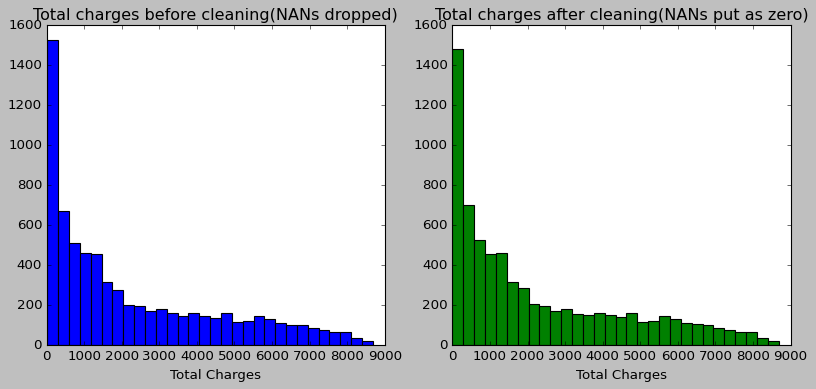

In [3]:
#Putting the raw dataset to show before and after matlib
df_raw = pd.read_csv('https://raw.githubusercontent.com/VedD376/ITAI-1371-ML-Dataset/main/WA_Fn-UseC_-Telco-Customer-Churn.csv')
#creates 2 plots for the before and after
fig, axes = plt.subplots(1, 2, figsize=(12,5))
before_Filling = pd.to_numeric(df_raw['TotalCharges'], errors='coerce')
#This plots the raw dataset as a histogram first
axes[0].hist(before_Filling.dropna(), bins=30, color='blue')
axes[0].set_title('Total charges before cleaning(NANs dropped)')
axes[0].set_xlabel('Total Charges')
#This first graph shows a high number of customers with a low amount billed
#This plots the raw dataset as a histogram first
axes[1].hist(df['TotalCharges'], bins=30, color='green')
axes[1].set_title('Total charges after cleaning(NANs put as zero)')
axes[1].set_xlabel('Total Charges')
plt.show()
#The before and after histograms are very similar because the number of rows changed was 11 out of 7000, which won't do much; however, this step is still important to make the machine more accurate,
#you need to do the small things that even though they may not make a huge visaul differnce it can still increase the accuarcy of the AI by some amount.
#which if this did not happen could cause problems later on in the process if this simple turing them into zeros did not occour.

In [4]:
#We now want to drop the customer ID as this increasing number can cause the machine to focus it's attentition on the last customer more than the first when both thier data is equally as imporant
df = df.drop('customerID', axis = 1)
df.columns
#Code done by Ved Dalwadi

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [5]:
#Now we want to split the data into testing, valadation, we will use holdout for now to further split the data
train_df, holdout_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df['Churn'])
#Split the hold out into valadation and test splits
val_df, test_df = train_test_split(holdout_df, test_size=0.50, random_state=42, stratify=holdout_df['Churn'])
#Now we will print each shape of the data split
print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)
#check the amount of no to yes churn
print("Train:", train_df['Churn'].value_counts(normalize=True).round(3).to_dict())
print("Validation:", val_df['Churn'].value_counts(normalize=True).round(3).to_dict())
print("Test:", test_df['Churn'].value_counts(normalize=True).round(3).to_dict())

Train shape: (4930, 20)
Validation shape: (1056, 20)
Test shape: (1057, 20)
Train: {'No': 0.735, 'Yes': 0.265}
Validation: {'No': 0.735, 'Yes': 0.265}
Test: {'No': 0.734, 'Yes': 0.266}


In [6]:
#Now we want to print the before and after of the dataset cleaning
print("Before cleaning (Raw)")
print(df_raw[['customerID', 'tenure', 'TotalCharges']].head(10))
print("After cleaning (Clean)")
print(df[[ 'tenure', 'TotalCharges']].head(10))

Before cleaning (Raw)
   customerID  tenure TotalCharges
0  7590-VHVEG       1        29.85
1  5575-GNVDE      34       1889.5
2  3668-QPYBK       2       108.15
3  7795-CFOCW      45      1840.75
4  9237-HQITU       2       151.65
5  9305-CDSKC       8        820.5
6  1452-KIOVK      22       1949.4
7  6713-OKOMC      10        301.9
8  7892-POOKP      28      3046.05
9  6388-TABGU      62      3487.95
After cleaning (Clean)
   tenure  TotalCharges
0       1         29.85
1      34       1889.50
2       2        108.15
3      45       1840.75
4       2        151.65
5       8        820.50
6      22       1949.40
7      10        301.90
8      28       3046.05
9      62       3487.95


In [7]:
# Th is to confirm that I am working only with the 70% training dataset
print("Trainng set shape:", train_df.shape)

# Display a sample of the training data
train_df.head()

Trainng set shape: (4930, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
5557,Female,0,No,No,5,Yes,No,Fiber optic,No,No,No,No,Yes,No,Month-to-month,No,Electronic check,80.20,384.25,No
2270,Female,1,No,No,3,Yes,No,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,86.85,220.95,Yes
6930,Female,0,Yes,No,3,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Credit card (automatic),75.15,216.75,Yes
2257,Female,0,No,No,60,Yes,Yes,DSL,No,No,Yes,Yes,Yes,Yes,One year,No,Credit card (automatic),80.55,4847.05,No
898,Female,0,No,No,12,Yes,No,Fiber optic,Yes,No,No,Yes,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),98.90,1120.95,Yes


In [8]:
# Display the column names and data types
train_df.info()

# Check for missing values in the training set
print("\nMissing values in each column:")
print(train_df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 4930 entries, 5557 to 5639
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            4930 non-null   object 
 1   SeniorCitizen     4930 non-null   int64  
 2   Partner           4930 non-null   object 
 3   Dependents        4930 non-null   object 
 4   tenure            4930 non-null   int64  
 5   PhoneService      4930 non-null   object 
 6   MultipleLines     4930 non-null   object 
 7   InternetService   4930 non-null   object 
 8   OnlineSecurity    4930 non-null   object 
 9   OnlineBackup      4930 non-null   object 
 10  DeviceProtection  4930 non-null   object 
 11  TechSupport       4930 non-null   object 
 12  StreamingTV       4930 non-null   object 
 13  StreamingMovies   4930 non-null   object 
 14  Contract          4930 non-null   object 
 15  PaperlessBilling  4930 non-null   object 
 16  PaymentMethod     4930 non-null   object 
 1

In [9]:
# Summary statistics for the numerical features assigned to my section
print("Summary statistics for tenure and MonthlyCharges:")
display(train_df[['tenure', 'MonthlyCharges']].describe())

# Frequency counts for the categorical features
print("\nContract type counts:")
display(train_df['Contract'].value_counts())

print("\nPayment method counts:")
display(train_df['PaymentMethod'].value_counts())

Summary statistics for tenure and MonthlyCharges:


,tenure,MonthlyCharges
count,4930.000000,4930.000000
mean,32.471197,64.950081
std,24.646350,30.243674
min,0.000000,18.400000
25%,9.000000,35.500000
50%,29.000000,70.575000
75%,56.000000,90.050000
max,72.000000,118.750000



Contract type counts:


,count
Contract,
Month-to-month,2704
Two year,1192
One year,1034



Payment method counts:


,count
PaymentMethod,
Electronic check,1654
Mailed check,1123
Bank transfer (automatic),1086
Credit card (automatic),1067


### Summary Statistics Analysis

The summary statistics provide an overview of customer tenure and monthly charges in the training data. The frequency tables also show which contract types and payment methods are most common. These features may be related to customer churn because contract commitment, length of service, and monthly cost can influence whether a customer remains with the company.

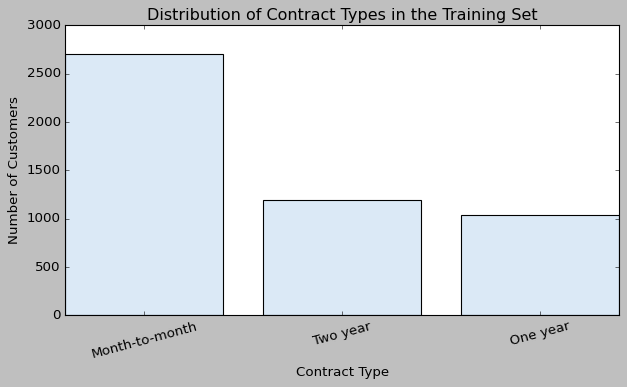

In [10]:
import matplotlib.pyplot as plt

# Display the distribution of customer contract types
contract_counts = train_df['Contract'].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(contract_counts.index, contract_counts.values)
plt.title('Distribution of Contract Types in the Training Set')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Contract Type Analysis

The chart shows how customers are distributed across month-to-month, one-year, and two-year contracts. Month-to-month customers may have more flexibility to leave the company, while customers with longer contracts may be less likely to churn.

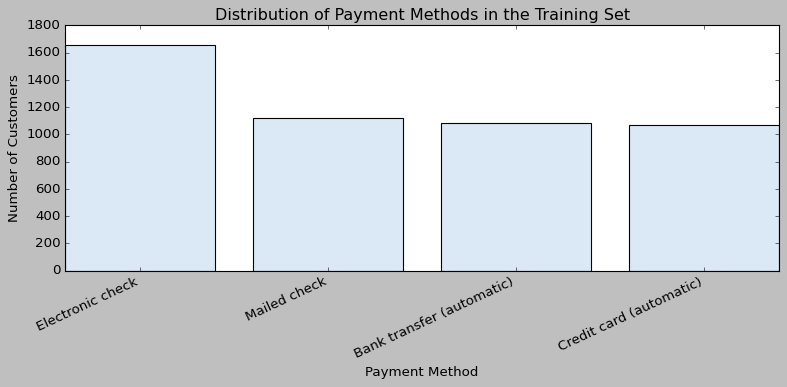

In [11]:
# Display the distribution of customer payment methods
payment_counts = train_df['PaymentMethod'].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(payment_counts.index, payment_counts.values)
plt.title('Distribution of Payment Methods in the Training Set')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

### Payment Method Analysis

This chart shows the payment methods used by customers in the training set. Reviewing payment methods may help identify whether customers using certain payment options are more likely to churn than others.

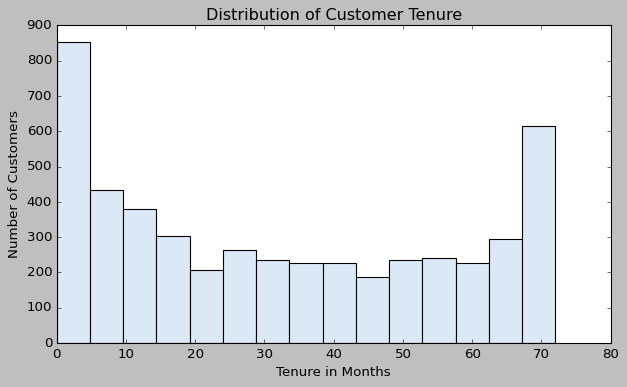

In [12]:
# Display the distribution of customer tenure
plt.figure(figsize=(8, 5))
plt.hist(train_df['tenure'], bins=15, edgecolor='black')
plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure in Months')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


### Tenure Analysis

The histogram shows how long customers have remained with the company. Customers with shorter tenure may still be deciding whether the service meets their needs, while customers with longer tenure may have developed greater loyalty to the company.

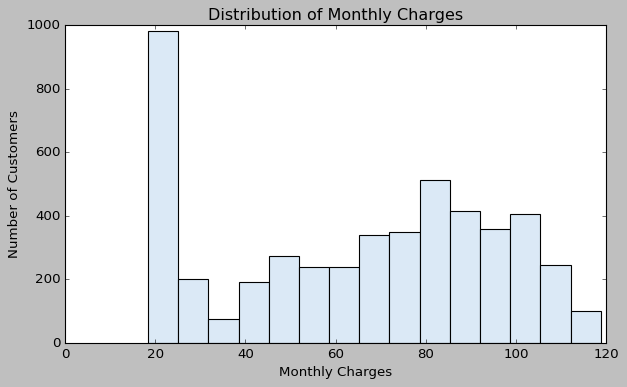

In [13]:
# Display the distribution of monthly customer charges
plt.figure(figsize=(8, 5))
plt.hist(train_df['MonthlyCharges'], bins=15, edgecolor='black')
plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

### Monthly Charges Analysis

The histogram shows the range of monthly charges paid by customers. Higher monthly costs may affect customer satisfaction and could be associated with a greater likelihood of churn.

Churn counts:
Churn
No     3622
Yes    1308
Name: count, dtype: int64

Churn percentages:
Churn
No     73.47
Yes    26.53
Name: proportion, dtype: float64


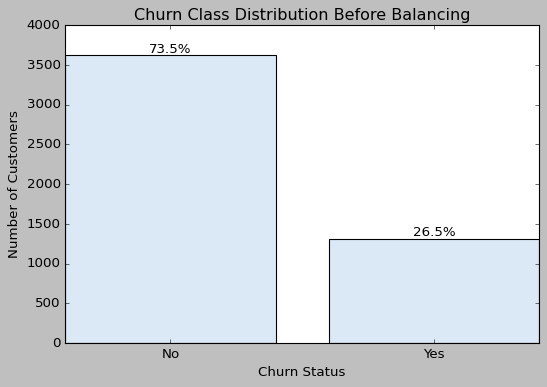

In [14]:
# Count the number and percentage of customers in each churn class
churn_counts = train_df['Churn'].value_counts()
churn_percentages = train_df['Churn'].value_counts(normalize=True) * 100

print("Churn counts:")
print(churn_counts)

print("\nChurn percentages:")
print(churn_percentages.round(2))

# Plot the class distribution
plt.figure(figsize=(7, 5))
bars = plt.bar(churn_counts.index, churn_counts.values)

plt.title('Churn Class Distribution Before Balancing')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

# Add percentages above each bar
for bar, label in zip(bars, churn_counts.index):
    percentage = churn_percentages[label]
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{percentage:.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

### Churn Class Distribution

The training data contains more customers who did not churn than customers who did churn. This class imbalance could cause a machine learning model to favor the majority class. A class-balancing method will be applied after the categorical data has been converted into numerical values.

In [15]:
# Create a copy so the original training set remains available
train_engineered = train_df.copy()

In [16]:
# Group customer tenure into meaningful categories
tenure_bins = [-1, 12, 24, 48, 72]
tenure_labels = [
    'New Customer',
    'Developing Customer',
    'Established Customer',
    'Long-Term Customer'
]

train_engineered['TenureGroup'] = pd.cut(
    train_engineered['tenure'],
    bins=tenure_bins,
    labels=tenure_labels
)

# Display a sample of the new feature
display(train_engineered[['tenure', 'TenureGroup']].head(10))

# Show the number of customers in each tenure group
print(train_engineered['TenureGroup'].value_counts().sort_index())

,tenure,TenureGroup
5557,5,New Customer
2270,3,New Customer
6930,3,New Customer
2257,60,Long-Term Customer
898,12,New Customer
3828,65,Long-Term Customer
2147,18,Developing Customer
3149,8,New Customer
5401,31,Established Customer
2062,66,Long-Term Customer


TenureGroup
New Customer            1537
Developing Customer      707
Established Customer    1118
Long-Term Customer      1568
Name: count, dtype: int64


In [17]:
# Service columns that indicate whether a customer subscribes to each service
service_columns = [
    'PhoneService',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

# Count each service marked "Yes"
train_engineered['NumberOfServices'] = (
    train_engineered[service_columns]
    .eq('Yes')
    .sum(axis=1)
)

# Display a sample of the new feature
display(
    train_engineered[
        service_columns + ['NumberOfServices']
    ].head(10)
)

print("\nNumber of services summary:")
print(train_engineered['NumberOfServices'].describe())

,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,NumberOfServices
5557,Yes,No,No,No,No,No,Yes,No,2
2270,Yes,No,No,No,Yes,No,Yes,No,3
6930,Yes,Yes,No,No,No,No,No,No,2
2257,Yes,Yes,No,No,Yes,Yes,Yes,Yes,6
898,Yes,No,Yes,No,No,Yes,Yes,Yes,5
3828,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,1
2147,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,1
3149,Yes,No,No,No,Yes,Yes,No,Yes,4
5401,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,1
2062,Yes,Yes,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,2



Number of services summary:
count    4930.000000
mean        3.389249
std         2.079083
min         0.000000
25%         1.000000
50%         3.000000
75%         5.000000
max         8.000000
Name: NumberOfServices, dtype: float64


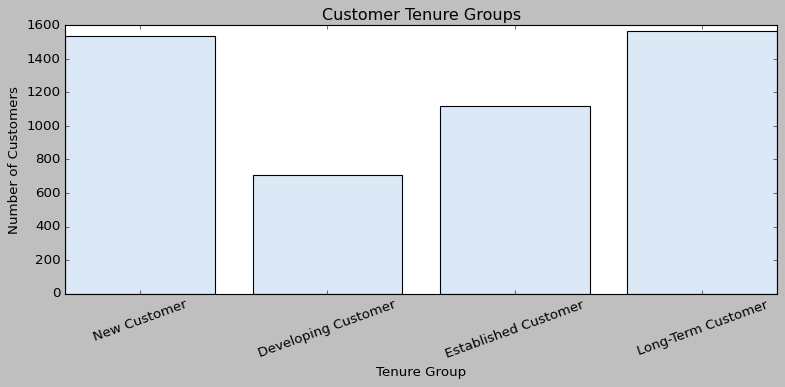

In [18]:
# Visualize the new tenure groups
tenure_group_counts = (
    train_engineered['TenureGroup']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))
plt.bar(
    tenure_group_counts.index.astype(str),
    tenure_group_counts.values
)
plt.title('Customer Tenure Groups')
plt.xlabel('Tenure Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

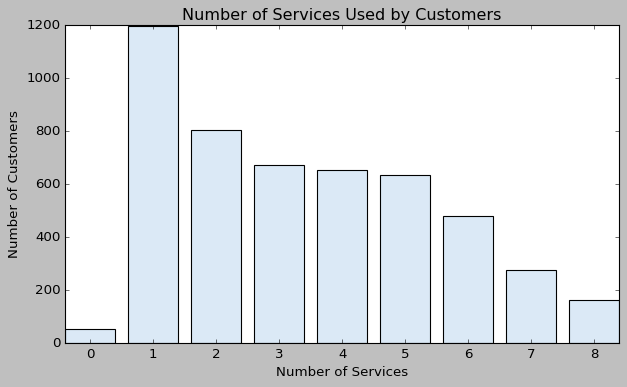

In [19]:
# Visualize the number of services used by customers
service_count_distribution = (
    train_engineered['NumberOfServices']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))
plt.bar(
    service_count_distribution.index.astype(str),
    service_count_distribution.values
)
plt.title('Number of Services Used by Customers')
plt.xlabel('Number of Services')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

In [20]:
# Compare selected columns before and after feature engineering
print("Sample before feature engineering:")
display(train_df[['tenure', 'Churn']].head())

print("\nSample after feature engineering:")
display(
    train_engineered[
        ['tenure', 'TenureGroup', 'NumberOfServices', 'Churn']
    ].head()
)

Sample before feature engineering:


,tenure,Churn
5557,5,No
2270,3,Yes
6930,3,Yes
2257,60,No
898,12,Yes



Sample after feature engineering:


,tenure,TenureGroup,NumberOfServices,Churn
5557,5,New Customer,2,No
2270,3,New Customer,3,Yes
6930,3,New Customer,2,Yes
2257,60,Long-Term Customer,6,No
898,12,New Customer,5,Yes


Class balancing is completed after the one-hot encoding section because SMOTE requires numerical features.

In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Preprocessing for the training data
train_person3 = train_df.copy()

print("Training data shape before Person 3 preprocessing:")
print(train_person3.shape)

print("\nFirst five rows before Person 3 preprocessing:")
print(train_person3.head())

Training data shape before Person 3 preprocessing:
(4930, 20)

First five rows before Person 3 preprocessing:
      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
5557  Female              0      No         No       5          Yes   
2270  Female              1      No         No       3          Yes   
6930  Female              0     Yes         No       3          Yes   
2257  Female              0      No         No      60          Yes   
898   Female              0      No         No      12          Yes   

     MultipleLines InternetService OnlineSecurity OnlineBackup  \
5557            No     Fiber optic             No           No   
2270            No     Fiber optic             No           No   
6930           Yes     Fiber optic             No           No   
2257           Yes             DSL             No           No   
898             No     Fiber optic            Yes           No   

     DeviceProtection TechSupport StreamingTV StreamingMovies     

In [22]:
object_columns = train_person3.select_dtypes(include=['object']).columns

for column in object_columns:
    train_person3[column] = train_person3[column].astype(str).str.strip()

service_columns = [
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

for column in service_columns:
    if column in train_person3.columns:
        train_person3[column] = train_person3[column].replace({
            'No internet service': 'No',
            'No phone service': 'No'
        })

print("Unique values after simplifying service-related columns:\n")

for column in service_columns:
    if column in train_person3.columns:
        print(column, ":", train_person3[column].unique())

Unique values after simplifying service-related columns:

MultipleLines : ['No' 'Yes']
OnlineSecurity : ['No' 'Yes']
OnlineBackup : ['No' 'Yes']
DeviceProtection : ['No' 'Yes']
TechSupport : ['No' 'Yes']
StreamingTV : ['Yes' 'No']
StreamingMovies : ['No' 'Yes']


In [23]:
# Pull out the target (Churn) BEFORE dropping it, so we still have the column to read
y_train_person3 = train_person3['Churn']

# Convert Churn from Yes/No into 1/0
# Yes = customer churned
# No = customer did not churn

y_train_person3 = y_train_person3.map({
    'No': 0,
    'Yes': 1
})

# Now drop Churn to build the feature set (X) used for encoding/scaling
X_train_person3 = train_person3.drop(columns=['Churn'])

print("Target value counts after converting Churn to 0 and 1:")
print(y_train_person3.value_counts())

print("\nTarget percentage distribution:")
print((y_train_person3.value_counts(normalize=True) * 100).round(2))

Target value counts after converting Churn to 0 and 1:
Churn
0    3622
1    1308
Name: count, dtype: int64

Target percentage distribution:
Churn
0    73.47
1    26.53
Name: proportion, dtype: float64


In [24]:
# Find remaining categorical columns that still contain text
categorical_columns = X_train_person3.select_dtypes(include=['object']).columns

print("Categorical columns before one-hot encoding:")
print(list(categorical_columns))

# One-hot encode categorical columns
X_train_encoded = pd.get_dummies(
    X_train_person3,
    columns=categorical_columns,
    drop_first=True
)

# This section will convert True/False columns into 1/0 integers
bool_columns = X_train_encoded.select_dtypes(include=['bool']).columns
X_train_encoded[bool_columns] = X_train_encoded[bool_columns].astype(int)

print("\nTraining data shape after one-hot encoding:")
print(X_train_encoded.shape)

print("\nFirst five rows after one-hot encoding:")
print(X_train_encoded.head())

Categorical columns before one-hot encoding:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Training data shape after one-hot encoding:
(4930, 23)

First five rows after one-hot encoding:
      SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
5557              0       5           80.20        384.25            0   
2270              1       3           86.85        220.95            0   
6930              0       3           75.15        216.75            0   
2257              0      60           80.55       4847.05            0   
898               0      12           98.90       1120.95            0   

      Partner_Yes  Dependents_Yes  PhoneService_Yes  MultipleLines_Yes  \
5557            0               0                 1                  0   
2270            0        

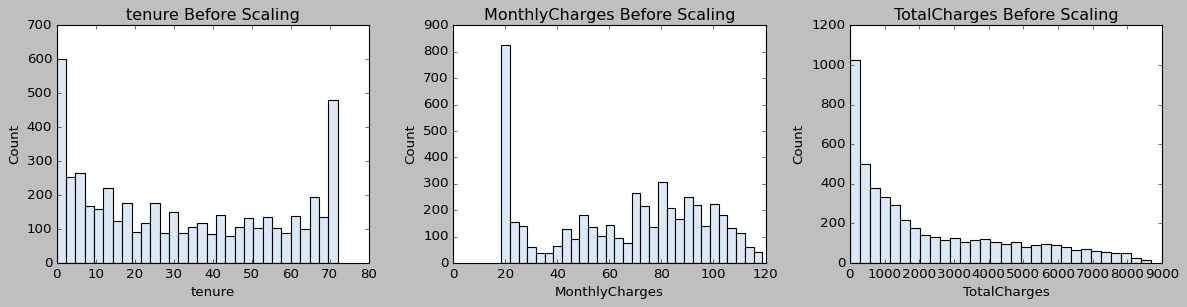

In [25]:
# The numeric columns I'm scaling
columns_to_scale = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Show distributions before scaling.
plt.figure(figsize=(15, 4))

for i, column in enumerate(columns_to_scale):
    plt.subplot(1, 3, i + 1)
    plt.hist(X_train_encoded[column], bins=30)
    plt.title(f'{column} Before Scaling')
    plt.xlabel(column)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [26]:
# StandardScaler to put numeric columns on a similar scale
scaler = StandardScaler()

X_train_scaled = X_train_encoded.copy()

X_train_scaled[columns_to_scale] = scaler.fit_transform(
    X_train_scaled[columns_to_scale]
)

print("First five rows after scaling tenure, MonthlyCharges, and TotalCharges:")
print(X_train_scaled[columns_to_scale].head())

print("\nSummary statistics after scaling:")
print(X_train_scaled[columns_to_scale].describe())

First five rows after scaling tenure, MonthlyCharges, and TotalCharges:
        tenure  MonthlyCharges  TotalCharges
5557 -1.114728        0.504286     -0.836504
2270 -1.195884        0.724189     -0.907742
6930 -1.195884        0.337292     -0.909574
2257  1.117066        0.515860      1.110332
898  -0.830682        1.122660     -0.515129

Summary statistics after scaling:
             tenure  MonthlyCharges  TotalCharges
count  4.930000e+03    4.930000e+03  4.930000e+03
mean   1.167423e-16    4.143632e-17 -4.359821e-17
std    1.000101e+00    1.000101e+00  1.000101e+00
min   -1.317619e+00   -1.539324e+00 -1.004128e+00
25%   -9.524160e-01   -9.738588e-01 -8.312369e-01
50%   -1.408545e-01    1.860055e-01 -3.988937e-01
75%    9.547535e-01    8.300071e-01  6.784417e-01
max    1.604003e+00    1.779062e+00  2.784499e+00


### Monepha class balancing with SMOTE

In [27]:


from imblearn.over_sampling import SMOTE

# Display the churn distribution before balancing
print("Class distribution before SMOTE:")
print(y_train_person3.value_counts())

print("\nClass percentages before SMOTE:")
print((y_train_person3.value_counts(normalize=True) * 100).round(2))

# Apply SMOTE only to the encoded and scaled training data
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled,
    y_train_person3
)

# Display the churn distribution after balancing
print("\nClass distribution after SMOTE:")
print(y_train_balanced.value_counts())

print("\nClass percentages after SMOTE:")
print((y_train_balanced.value_counts(normalize=True) * 100).round(2))

print("\nBalanced training data shape:")
print(X_train_balanced.shape)

Class distribution before SMOTE:
Churn
0    3622
1    1308
Name: count, dtype: int64

Class percentages before SMOTE:
Churn
0    73.47
1    26.53
Name: proportion, dtype: float64

Class distribution after SMOTE:
Churn
0    3622
1    3622
Name: count, dtype: int64

Class percentages after SMOTE:
Churn
0    50.0
1    50.0
Name: proportion, dtype: float64

Balanced training data shape:
(7244, 23)


### Monepha continued

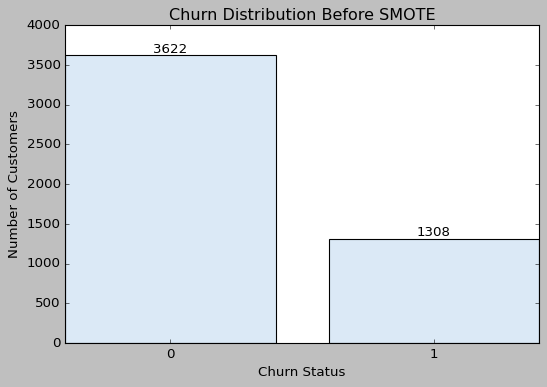

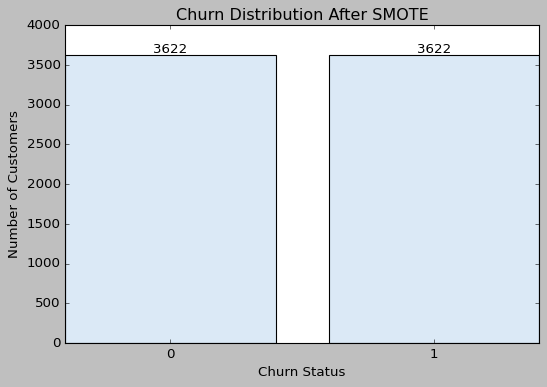

In [28]:


# Create class counts before and after SMOTE
before_counts = y_train_person3.value_counts().sort_index()
after_counts = y_train_balanced.value_counts().sort_index()

# Plot the class distribution before balancing
plt.figure(figsize=(7, 5))
bars_before = plt.bar(
    before_counts.index.astype(str),
    before_counts.values
)

plt.title('Churn Distribution Before SMOTE')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

for bar in bars_before:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

# Plot the class distribution after balancing
plt.figure(figsize=(7, 5))
bars_after = plt.bar(
    after_counts.index.astype(str),
    after_counts.values
)

plt.title('Churn Distribution After SMOTE')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

for bar in bars_after:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

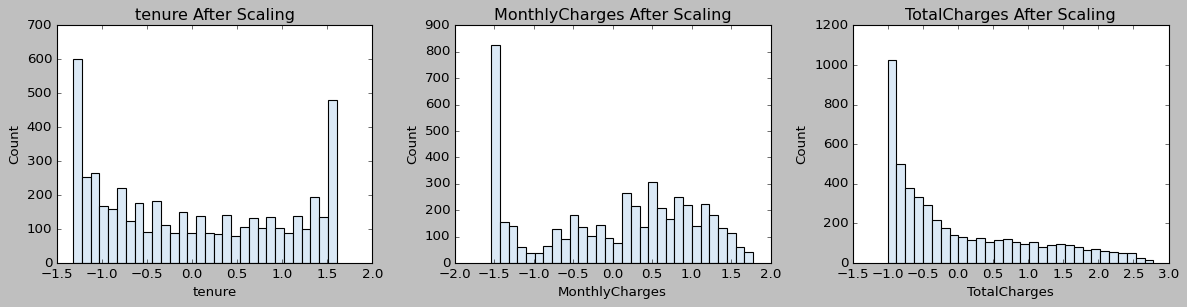

In [29]:
# display for distributions after scaling
plt.figure(figsize=(15, 4))

for i, column in enumerate(columns_to_scale):
    plt.subplot(1, 3, i + 1)
    plt.hist(X_train_scaled[column], bins=30)
    plt.title(f'{column} After Scaling')
    plt.xlabel(column)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [30]:
#Use the same cleanign Nigel used for train person 3 on valadation set
val_person3 = val_df.copy()

object_columns = val_person3.select_dtypes(include=['object']).columns
for column in object_columns:
    val_person3[column] = val_person3[column].astype(str).str.strip()

service_columns = [
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]
#replaces complex wording for machine to simple no
for column in service_columns:
    if column in val_person3.columns:
        val_person3[column] = val_person3[column].replace({
            'No internet service': 'No',
            'No phone service': 'No'
        })
#Now I pulled out and converted the target just like train
y_val = val_person3['Churn'].map({'No': 0, 'Yes': 1})
X_val_person3 = val_person3.drop(columns=['Churn'])

# I now need to one hot encode and allagin the columns to match X train encode
val_categorical_columns = X_val_person3.select_dtypes(include=['object']).columns
X_val_encoded = pd.get_dummies(X_val_person3, columns=val_categorical_columns, drop_first=True)
#This is so I can allgin the colloums
bool_columns = X_val_encoded.select_dtypes(include=['bool']).columns
X_val_encoded[bool_columns] = X_val_encoded[bool_columns].astype(int)

X_val_encoded = X_val_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# Now I used the scaler that was already fit on train
X_val_scaled = X_val_encoded.copy()
X_val_scaled[columns_to_scale] = scaler.transform(X_val_scaled[columns_to_scale])
# Now I print the shape after pipeline and columns that match train
print("Validation set shape after pipeline:", X_val_scaled.shape)
print("Val columns match train:", list(X_val_scaled.columns) == list(X_train_encoded.columns))

Validation set shape after pipeline: (1056, 23)
Val columns match train: True


In [31]:
# I do all previous things form last cell but now for test
test_person3 = test_df.copy()

object_columns = test_person3.select_dtypes(include=['object']).columns
for column in object_columns:
    test_person3[column] = test_person3[column].astype(str).str.strip()

service_columns = [
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]
#replaces complex wording for machine to simple no
for column in service_columns:
    if column in test_person3.columns:
        test_person3[column] = test_person3[column].replace({
            'No internet service': 'No',
            'No phone service': 'No'
        })
#Now I pulled out and converted the target just like train
y_test = test_person3['Churn'].map({'No': 0, 'Yes': 1})
X_test_person3 = test_person3.drop(columns=['Churn'])

# I now need to one hot encode and allagin the columns to match X train encode
test_categorical_columns = X_test_person3.select_dtypes(include=['object']).columns
X_test_encoded = pd.get_dummies(X_test_person3, columns=test_categorical_columns, drop_first=True)
#This is so I can allgin the colloums
bool_columns = X_test_encoded.select_dtypes(include=['bool']).columns
X_test_encoded[bool_columns] = X_test_encoded[bool_columns].astype(int)

X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# Now I used the scaler that was already fit on train
X_test_scaled = X_test_encoded.copy()
X_test_scaled[columns_to_scale] = scaler.transform(X_test_scaled[columns_to_scale])
# Now I print the shape after pipeline and columns that match train
print("test set shape after pipeline:", X_test_scaled.shape)
print("test columns match train:", list(X_test_scaled.columns) == list(X_train_encoded.columns))

test set shape after pipeline: (1057, 23)
test columns match train: True


In [32]:
#Now I trained logistic regression on the SMOTE balanced training set
log_reg_model = LogisticRegression(max_iter=1000, random_state=42)
log_reg_model.fit(X_train_balanced, y_train_balanced)
#Now lets test how valadation data split does
y_val_pred_logreg = log_reg_model.predict(X_val_scaled)
y_val_proba_logreg = log_reg_model.predict_proba(X_val_scaled)[:, 1]
print("Logistic Regression for valadation data split")
print("Accuracy:", accuracy_score(y_val, y_val_pred_logreg))
print("Precision:", precision_score(y_val, y_val_pred_logreg))
print("Recall:", recall_score(y_val, y_val_pred_logreg))
print("F1 Score:", f1_score(y_val, y_val_pred_logreg))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_logreg))
print("Confusion Matrix")
print(confusion_matrix(y_val, y_val_pred_logreg))
#Now lets see how test data split does
y_test_pred_logreg = log_reg_model.predict(X_test_scaled)
y_test_proba_logreg = log_reg_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression for test data split")
print("Accuracy:", accuracy_score(y_test, y_test_pred_logreg))
print("Precision:", precision_score(y_test, y_test_pred_logreg))
print("Recall:", recall_score(y_test, y_test_pred_logreg))
print("F1 Score:", f1_score(y_test, y_test_pred_logreg))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_logreg))
print("Confusion Matrix")
print(confusion_matrix(y_test, y_test_pred_logreg))

# I am now going to put all the resukts in a list so it becomes easier in the future when I need to pull all 6
model_results = []
model_results.append({
    'Model': 'Logistic Regression',
    'Dataset': 'Validation',
    'Accuracy': accuracy_score(y_val, y_val_pred_logreg),
    'Precision': precision_score(y_val, y_val_pred_logreg),
    'Recall': recall_score(y_val, y_val_pred_logreg),
    'F1 Score': f1_score(y_val, y_val_pred_logreg),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_logreg)
})

model_results.append({
    'Model': 'Logistic Regression',
    'Dataset': 'Test',
    'Accuracy': accuracy_score(y_test, y_test_pred_logreg),
    'Precision': precision_score(y_test, y_test_pred_logreg),
    'Recall': recall_score(y_test, y_test_pred_logreg),
    'F1 Score': f1_score(y_test, y_test_pred_logreg),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba_logreg)
})

Logistic Regression for valadation data split
Accuracy: 0.75
Precision: 0.5190476190476191
Recall: 0.7785714285714286
F1 Score: 0.6228571428571429
ROC-AUC: 0.831997882916053
Confusion Matrix
[[574 202]
 [ 62 218]]
Logistic Regression for test data split
Accuracy: 0.7634815515610217
Precision: 0.5415549597855228
Recall: 0.7188612099644128
F1 Score: 0.617737003058104
ROC-AUC: 0.8374775287082217
Confusion Matrix
[[605 171]
 [ 79 202]]


In [33]:
#Now I will bascilly take the same code form beofore but now make it into a decesion tree classifer
#Now I trained decesion tree on the SMOTE balanced training set
tree_model = DecisionTreeClassifier(random_state=42, max_depth=5)
tree_model.fit(X_train_balanced, y_train_balanced)

#Now lets test how valadation data split does
y_val_pred_tree = tree_model.predict(X_val_scaled)
y_val_proba_tree = tree_model.predict_proba(X_val_scaled)[:, 1]

print("Decision Tree for valadation data split")
print("Accuracy:", accuracy_score(y_val, y_val_pred_tree))
print("Precision:", precision_score(y_val, y_val_pred_tree))
print("Recall:", recall_score(y_val, y_val_pred_tree))
print("F1 Score:", f1_score(y_val, y_val_pred_tree))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_tree))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_tree))

#Now lets see how test data split does
y_test_pred_tree = tree_model.predict(X_test_scaled)
y_test_proba_tree = tree_model.predict_proba(X_test_scaled)[:, 1]

print("Decision Tree for test data split")
print("Accuracy:", accuracy_score(y_test, y_test_pred_tree))
print("Precision:", precision_score(y_test, y_test_pred_tree))
print("Recall:", recall_score(y_test, y_test_pred_tree))
print("F1 Score:", f1_score(y_test, y_test_pred_tree))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_tree))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_tree))
#The first time printing this this shows 99% which means major overfitting so I added a max depth to the model
print("Training Accuracy:", accuracy_score(y_train_balanced, tree_model.predict(X_train_balanced)))

# Add results to the list
model_results.append({
    'Model': 'Decision Tree',
    'Dataset': 'Validation',
    'Accuracy': accuracy_score(y_val, y_val_pred_tree),
    'Precision': precision_score(y_val, y_val_pred_tree),
    'Recall': recall_score(y_val, y_val_pred_tree),
    'F1 Score': f1_score(y_val, y_val_pred_tree),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_tree)
})

model_results.append({
    'Model': 'Decision Tree',
    'Dataset': 'Test',
    'Accuracy': accuracy_score(y_test, y_test_pred_tree),
    'Precision': precision_score(y_test, y_test_pred_tree),
    'Recall': recall_score(y_test, y_test_pred_tree),
    'F1 Score': f1_score(y_test, y_test_pred_tree),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba_tree)
})

Decision Tree for valadation data split
Accuracy: 0.7547348484848485
Precision: 0.5259259259259259
Recall: 0.7607142857142857
F1 Score: 0.621897810218978
ROC-AUC: 0.827519790132548
Confusion Matrix:
[[584 192]
 [ 67 213]]
Decision Tree for test data split
Accuracy: 0.7530747398297067
Precision: 0.5259067357512953
Recall: 0.7224199288256228
F1 Score: 0.6086956521739131
ROC-AUC: 0.8166273801225373
Confusion Matrix:
[[593 183]
 [ 78 203]]
Training Accuracy: 0.7711209276642739


In [34]:
#Again I will use a very simillar code from the last two to make a random forset
#Now I trained random forest on the SMOTE balanced training set

forest_model = RandomForestClassifier(random_state=42, max_depth=5)
forest_model.fit(X_train_balanced, y_train_balanced)

#Now lets test how valadation data split does
y_val_pred_forest = forest_model.predict(X_val_scaled)
y_val_proba_forest = forest_model.predict_proba(X_val_scaled)[:, 1]

print("Random Forest for valadation data split")
print("Accuracy:", accuracy_score(y_val, y_val_pred_forest))
print("Precision:", precision_score(y_val, y_val_pred_forest))
print("Recall:", recall_score(y_val, y_val_pred_forest))
print("F1 Score:", f1_score(y_val, y_val_pred_forest))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_forest))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_forest))

#Now lets see how test data split does
y_test_pred_forest = forest_model.predict(X_test_scaled)
y_test_proba_forest = forest_model.predict_proba(X_test_scaled)[:, 1]

print("Random Forest for test data split")
print("Accuracy:", accuracy_score(y_test, y_test_pred_forest))
print("Precision:", precision_score(y_test, y_test_pred_forest))
print("Recall:", recall_score(y_test, y_test_pred_forest))
print("F1 Score:", f1_score(y_test, y_test_pred_forest))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_forest))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_forest))

#Same as last time making sure of no under or overfitting
print("Training Accuracy:", accuracy_score(y_train_balanced, forest_model.predict(X_train_balanced)))
#I tested this both with and without max depth and it shows that even though this is usually meant to underfit, I still got a score 99%
#With my other methods only geting up to 80% on the high end and on the low end 50%

# add results to list
model_results.append({
    'Model': 'Random Forest',
    'Dataset': 'Validation',
    'Accuracy': accuracy_score(y_val, y_val_pred_forest),
    'Precision': precision_score(y_val, y_val_pred_forest),
    'Recall': recall_score(y_val, y_val_pred_forest),
    'F1 Score': f1_score(y_val, y_val_pred_forest),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_forest)
})

model_results.append({
    'Model': 'Random Forest',
    'Dataset': 'Test',
    'Accuracy': accuracy_score(y_test, y_test_pred_forest),
    'Precision': precision_score(y_test, y_test_pred_forest),
    'Recall': recall_score(y_test, y_test_pred_forest),
    'F1 Score': f1_score(y_test, y_test_pred_forest),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba_forest)
})

Random Forest for valadation data split
Accuracy: 0.7509469696969697
Precision: 0.5191873589164786
Recall: 0.8214285714285714
F1 Score: 0.636237897648686
ROC-AUC: 0.8447118924889544
Confusion Matrix:
[[563 213]
 [ 50 230]]
Random Forest for test data split
Accuracy: 0.7521286660359509
Precision: 0.5235732009925558
Recall: 0.7508896797153025
F1 Score: 0.6169590643274854
ROC-AUC: 0.8403552298492131
Confusion Matrix:
[[584 192]
 [ 70 211]]
Training Accuracy: 0.8008006626173385


In [35]:
#Again, I will use a very similar code from the last two to make an XGBoost
#Now I trained XGBoost on the SMOTE balanced training set
xgb_model = xgb.XGBClassifier(max_depth=5, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_balanced, y_train_balanced)

#Now lets test how valadation data split does
y_val_pred_xgb = xgb_model.predict(X_val_scaled)
y_val_proba_xgb = xgb_model.predict_proba(X_val_scaled)[:, 1]

print("Gradient Boosting (XGBoost) for valadation data split")
print("Accuracy:", accuracy_score(y_val, y_val_pred_xgb))
print("Precision:", precision_score(y_val, y_val_pred_xgb))
print("Recall:", recall_score(y_val, y_val_pred_xgb))
print("F1 Score:", f1_score(y_val, y_val_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_xgb))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_xgb))

#Now lets see how test  data split does
y_test_pred_xgb = xgb_model.predict(X_test_scaled)
y_test_proba_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("Gradient Boosting (XGBoost) for test data split")
print("Accuracy:", accuracy_score(y_test, y_test_pred_xgb))
print("Precision:", precision_score(y_test, y_test_pred_xgb))
print("Recall:", recall_score(y_test, y_test_pred_xgb))
print("F1 Score:", f1_score(y_test, y_test_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_xgb))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_xgb))

#Same as last time making sure of no under or overfitting
print("Training Accuracy:", accuracy_score(y_train_balanced, xgb_model.predict(X_train_balanced)))

#Add results to list
model_results.append({
    'Model': 'Gradient Boosting (XGBoost)',
    'Dataset': 'Validation',
    'Accuracy': accuracy_score(y_val, y_val_pred_xgb),
    'Precision': precision_score(y_val, y_val_pred_xgb),
    'Recall': recall_score(y_val, y_val_pred_xgb),
    'F1 Score': f1_score(y_val, y_val_pred_xgb),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_xgb)
})

model_results.append({
    'Model': 'Gradient Boosting (XGBoost)',
    'Dataset': 'Test',
    'Accuracy': accuracy_score(y_test, y_test_pred_xgb),
    'Precision': precision_score(y_test, y_test_pred_xgb),
    'Recall': recall_score(y_test, y_test_pred_xgb),
    'F1 Score': f1_score(y_test, y_test_pred_xgb),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba_xgb)
})

Gradient Boosting (XGBoost) for valadation data split
Accuracy: 0.7585227272727273
Precision: 0.5348189415041783
Recall: 0.6857142857142857
F1 Score: 0.6009389671361502
ROC-AUC: 0.813965850515464
Confusion Matrix:
[[609 167]
 [ 88 192]]
Gradient Boosting (XGBoost) for test data split
Accuracy: 0.771050141911069
Precision: 0.56
Recall: 0.6476868327402135
F1 Score: 0.6006600660066007
ROC-AUC: 0.823368767656015
Confusion Matrix:
[[633 143]
 [ 99 182]]
Training Accuracy: 0.9244892324682495


In [36]:
#Same approach as before, now training a K-Nearest Neighbors model
#KNN works off distance between points so it relies on the scaling we already did
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_balanced, y_train_balanced)

#Now lets test how valadation data split does
y_val_pred_knn = knn_model.predict(X_val_scaled)
y_val_proba_knn = knn_model.predict_proba(X_val_scaled)[:, 1]

print("K-Nearest Neighbors for valadation data split")
print("Accuracy:", accuracy_score(y_val, y_val_pred_knn))
print("Precision:", precision_score(y_val, y_val_pred_knn))
print("Recall:", recall_score(y_val, y_val_pred_knn))
print("F1 Score:", f1_score(y_val, y_val_pred_knn))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_knn))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_knn))

#Now lets see how test  data split does
y_test_pred_knn = knn_model.predict(X_test_scaled)
y_test_proba_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

print("K-Nearest Neighbors for test data split")
print("Accuracy:", accuracy_score(y_test, y_test_pred_knn))
print("Precision:", precision_score(y_test, y_test_pred_knn))
print("Recall:", recall_score(y_test, y_test_pred_knn))
print("F1 Score:", f1_score(y_test, y_test_pred_knn))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_knn))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_knn))

#Same as last time making sure of no under or overfitting
print("Training Accuracy:", accuracy_score(y_train_balanced, knn_model.predict(X_train_balanced)))

#Add results to list
model_results.append({
    'Model': 'K-Nearest Neighbors',
    'Dataset': 'Validation',
    'Accuracy': accuracy_score(y_val, y_val_pred_knn),
    'Precision': precision_score(y_val, y_val_pred_knn),
    'Recall': recall_score(y_val, y_val_pred_knn),
    'F1 Score': f1_score(y_val, y_val_pred_knn),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_knn)
})

model_results.append({
    'Model': 'K-Nearest Neighbors',
    'Dataset': 'Test',
    'Accuracy': accuracy_score(y_test, y_test_pred_knn),
    'Precision': precision_score(y_test, y_test_pred_knn),
    'Recall': recall_score(y_test, y_test_pred_knn),
    'F1 Score': f1_score(y_test, y_test_pred_knn),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba_knn)
})

K-Nearest Neighbors for valadation data split
Accuracy: 0.7272727272727273
Precision: 0.49099099099099097
Recall: 0.7785714285714286
F1 Score: 0.6022099447513812
ROC-AUC: 0.7992751288659794
Confusion Matrix:
[[550 226]
 [ 62 218]]
K-Nearest Neighbors for test data split
Accuracy: 0.7123935666982024
Precision: 0.4724220623501199
Recall: 0.701067615658363
F1 Score: 0.5644699140401146
ROC-AUC: 0.7790154822614375
Confusion Matrix:
[[556 220]
 [ 84 197]]
Training Accuracy: 0.8670623964660409


In [37]:
#Same approach as before, now training a Support Vector Classifier
#probability=True is needed here so we can get predict_proba for ROC-AUC, off by default in SVC
svc_model = SVC(kernel='rbf', probability=True, random_state=42)
svc_model.fit(X_train_balanced, y_train_balanced)

#Now lets test how valadation data split does
y_val_pred_svc = svc_model.predict(X_val_scaled)
y_val_proba_svc = svc_model.predict_proba(X_val_scaled)[:, 1]

print("Support Vector Classifier for valadation data split")
print("Accuracy:", accuracy_score(y_val, y_val_pred_svc))
print("Precision:", precision_score(y_val, y_val_pred_svc))
print("Recall:", recall_score(y_val, y_val_pred_svc))
print("F1 Score:", f1_score(y_val, y_val_pred_svc))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_svc))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_svc))

#Now lets see how test  data split does
y_test_pred_svc = svc_model.predict(X_test_scaled)
y_test_proba_svc = svc_model.predict_proba(X_test_scaled)[:, 1]

print("Support Vector Classifier for test data split")
print("Accuracy:", accuracy_score(y_test, y_test_pred_svc))
print("Precision:", precision_score(y_test, y_test_pred_svc))
print("Recall:", recall_score(y_test, y_test_pred_svc))
print("F1 Score:", f1_score(y_test, y_test_pred_svc))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_svc))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_svc))

#Same as last time making sure of no under or overfitting
print("Training Accuracy:", accuracy_score(y_train_balanced, svc_model.predict(X_train_balanced)))

#Add results to list
model_results.append({
    'Model': 'Support Vector Classifier',
    'Dataset': 'Validation',
    'Accuracy': accuracy_score(y_val, y_val_pred_svc),
    'Precision': precision_score(y_val, y_val_pred_svc),
    'Recall': recall_score(y_val, y_val_pred_svc),
    'F1 Score': f1_score(y_val, y_val_pred_svc),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_svc)
})

model_results.append({
    'Model': 'Support Vector Classifier',
    'Dataset': 'Test',
    'Accuracy': accuracy_score(y_test, y_test_pred_svc),
    'Precision': precision_score(y_test, y_test_pred_svc),
    'Recall': recall_score(y_test, y_test_pred_svc),
    'F1 Score': f1_score(y_test, y_test_pred_svc),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba_svc)
})

Support Vector Classifier for valadation data split
Accuracy: 0.7642045454545454
Precision: 0.5390428211586902
Recall: 0.7642857142857142
F1 Score: 0.6322008862629247
ROC-AUC: 0.825623619293078
Confusion Matrix:
[[593 183]
 [ 66 214]]
Support Vector Classifier for test data split
Accuracy: 0.771996215704825
Precision: 0.5540540540540541
Recall: 0.7295373665480427
F1 Score: 0.6298003072196621
ROC-AUC: 0.8273700333859191
Confusion Matrix:
[[611 165]
 [ 76 205]]
Training Accuracy: 0.8268912203202651


In [38]:
#Now I turned the list of every model's results into one dataframe
results_df = pd.DataFrame(model_results)

#Now I will round the numbers so it becomes easier to read
results_df = results_df.round(4)

#Now I split it into 2 diffrent views So I can look at them side by side
validation_results = results_df[results_df['Dataset'] == 'Validation'].sort_values('F1 Score', ascending=False)
test_results = results_df[results_df['Dataset'] == 'Test'].sort_values('F1 Score', ascending=False)

print("Validation Results, ranked by F1 Score")
print(validation_results)

print("Test Results, ranked by F1 Score")
print(test_results)

Validation Results, ranked by F1 Score
                          Model     Dataset  Accuracy  Precision  Recall  \
4                 Random Forest  Validation    0.7509     0.5192  0.8214   
10    Support Vector Classifier  Validation    0.7642     0.5390  0.7643   
0           Logistic Regression  Validation    0.7500     0.5190  0.7786   
2                 Decision Tree  Validation    0.7547     0.5259  0.7607   
8           K-Nearest Neighbors  Validation    0.7273     0.4910  0.7786   
6   Gradient Boosting (XGBoost)  Validation    0.7585     0.5348  0.6857   

    F1 Score  ROC-AUC  
4     0.6362   0.8447  
10    0.6322   0.8256  
0     0.6229   0.8320  
2     0.6219   0.8275  
8     0.6022   0.7993  
6     0.6009   0.8140  
Test Results, ranked by F1 Score
                          Model Dataset  Accuracy  Precision  Recall  \
11    Support Vector Classifier    Test    0.7720     0.5541  0.7295   
1           Logistic Regression    Test    0.7635     0.5416  0.7189   
5          

In [39]:
#Now I will lookup any trained model so I cna just use it's name
model_objects = {
    'Logistic Regression': log_reg_model,
    'Decision Tree': tree_model,
    'Random Forest': forest_model,
    'Gradient Boosting (XGBoost)': xgb_model,
    'K-Nearest Neighbors': knn_model,
    'Support Vector Classifier': svc_model
}

# Now I will pick the top 3 models based on Validation F1 Score I already got this from the table above
top_3_names = validation_results['Model'].head(3).tolist()
print("Top 3 models by Validation F1 Score:", top_3_names)

#Now I need to build the estimator list the voting classifier needs
voting_estimators = [(name, model_objects[name]) for name in top_3_names]

#Now I will soft vote avarges for predicting probility
voting_model = VotingClassifier(estimators=voting_estimators, voting='soft')
voting_model.fit(X_train_balanced, y_train_balanced)

#Now lets test how valadation data split does
y_val_pred_voting = voting_model.predict(X_val_scaled)
y_val_proba_voting = voting_model.predict_proba(X_val_scaled)[:, 1]

print("Voting Classifier for valadation data split")
print("Accuracy:", accuracy_score(y_val, y_val_pred_voting))
print("Precision:", precision_score(y_val, y_val_pred_voting))
print("Recall:", recall_score(y_val, y_val_pred_voting))
print("F1 Score:", f1_score(y_val, y_val_pred_voting))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_voting))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_voting))

#Now lets see how test  data split does
y_test_pred_voting = voting_model.predict(X_test_scaled)
y_test_proba_voting = voting_model.predict_proba(X_test_scaled)[:, 1]

print("Voting Classifier for test data split")
print("Accuracy:", accuracy_score(y_test, y_test_pred_voting))
print("Precision:", precision_score(y_test, y_test_pred_voting))
print("Recall:", recall_score(y_test, y_test_pred_voting))
print("F1 Score:", f1_score(y_test, y_test_pred_voting))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_voting))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_voting))

#Same as last time making sure of no under or overfitting
print("Training Accuracy:", accuracy_score(y_train_balanced, voting_model.predict(X_train_balanced)))

#Add results to list
model_results.append({
    'Model': 'Voting Classifier (Top 3)',
    'Dataset': 'Validation',
    'Accuracy': accuracy_score(y_val, y_val_pred_voting),
    'Precision': precision_score(y_val, y_val_pred_voting),
    'Recall': recall_score(y_val, y_val_pred_voting),
    'F1 Score': f1_score(y_val, y_val_pred_voting),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_voting)
})

model_results.append({
    'Model': 'Voting Classifier (Top 3)',
    'Dataset': 'Test',
    'Accuracy': accuracy_score(y_test, y_test_pred_voting),
    'Precision': precision_score(y_test, y_test_pred_voting),
    'Recall': recall_score(y_test, y_test_pred_voting),
    'F1 Score': f1_score(y_test, y_test_pred_voting),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba_voting)
})

Top 3 models by Validation F1 Score: ['Random Forest', 'Support Vector Classifier', 'Logistic Regression']
Voting Classifier for valadation data split
Accuracy: 0.759469696969697
Precision: 0.5317073170731708
Recall: 0.7785714285714286
F1 Score: 0.6318840579710145
ROC-AUC: 0.8398310935198823
Confusion Matrix:
[[584 192]
 [ 62 218]]
Voting Classifier for test data split
Accuracy: 0.771996215704825
Precision: 0.5543478260869565
Recall: 0.7259786476868327
F1 Score: 0.6286594761171033
ROC-AUC: 0.8427559892871557
Confusion Matrix:
[[612 164]
 [ 77 204]]
Training Accuracy: 0.8163997791275538


In [40]:
#Now I will use bayesian model averaging which will weigh the top 3 models by Valadation score

bayesian_weights = validation_results.set_index('Model').loc[top_3_names, 'F1 Score']
bayesian_weights = bayesian_weights / bayesian_weights.sum()

print("Bayesian weights (based on Validation F1 Score)")
print(bayesian_weights)

#Now I will Weigh the average of each model's predicted probability on validation
y_val_proba_bayes = sum(
    bayesian_weights[name] * model_objects[name].predict_proba(X_val_scaled)[:, 1]
    for name in top_3_names
)
y_val_pred_bayes = (y_val_proba_bayes >= 0.5).astype(int)

print("Bayesian Ensemble for valadation data split")
print("Accuracy:", accuracy_score(y_val, y_val_pred_bayes))
print("Precision:", precision_score(y_val, y_val_pred_bayes))
print("Recall:", recall_score(y_val, y_val_pred_bayes))
print("F1 Score:", f1_score(y_val, y_val_pred_bayes))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_bayes))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_bayes))

#Now I will Weigh the average of each model's predicted probability on test
y_test_proba_bayes = sum(
    bayesian_weights[name] * model_objects[name].predict_proba(X_test_scaled)[:, 1]
    for name in top_3_names
)
y_test_pred_bayes = (y_test_proba_bayes >= 0.5).astype(int)

print("Bayesian Ensemble for test data split")
print("Accuracy:", accuracy_score(y_test, y_test_pred_bayes))
print("Precision:", precision_score(y_test, y_test_pred_bayes))
print("Recall:", recall_score(y_test, y_test_pred_bayes))
print("F1 Score:", f1_score(y_test, y_test_pred_bayes))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_bayes))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_bayes))

#Add results to list
model_results.append({
    'Model': 'Bayesian Ensemble',
    'Dataset': 'Validation',
    'Accuracy': accuracy_score(y_val, y_val_pred_bayes),
    'Precision': precision_score(y_val, y_val_pred_bayes),
    'Recall': recall_score(y_val, y_val_pred_bayes),
    'F1 Score': f1_score(y_val, y_val_pred_bayes),
    'ROC-AUC': roc_auc_score(y_val, y_val_proba_bayes)
})

model_results.append({
    'Model': 'Bayesian Ensemble',
    'Dataset': 'Test',
    'Accuracy': accuracy_score(y_test, y_test_pred_bayes),
    'Precision': precision_score(y_test, y_test_pred_bayes),
    'Recall': recall_score(y_test, y_test_pred_bayes),
    'F1 Score': f1_score(y_test, y_test_pred_bayes),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba_bayes)
})

Bayesian weights (based on Validation F1 Score)
Model
Random Forest                0.336382
Support Vector Classifier    0.334267
Logistic Regression          0.329350
Name: F1 Score, dtype: float64
Bayesian Ensemble for valadation data split
Accuracy: 0.7585227272727273
Precision: 0.5304136253041363
Recall: 0.7785714285714286
F1 Score: 0.6309696092619392
ROC-AUC: 0.8398034793814433
Confusion Matrix:
[[583 193]
 [ 62 218]]
Bayesian Ensemble for test data split
Accuracy: 0.771996215704825
Precision: 0.5543478260869565
Recall: 0.7259786476868327
F1 Score: 0.6286594761171033
ROC-AUC: 0.842792677110467
Confusion Matrix:
[[612 164]
 [ 77 204]]


In [41]:
#Final Print of all models
final_results_df = pd.DataFrame(model_results)
final_results_df = final_results_df.round(4)

#Split into validation and test views, same as before, but now with all 8 models
final_validation_results = final_results_df[final_results_df['Dataset'] == 'Validation'].sort_values('F1 Score', ascending=False)
final_test_results = final_results_df[final_results_df['Dataset'] == 'Test'].sort_values('F1 Score', ascending=False)

print("Final Validation Results, ranked by F1 Score (all models + ensembles)")
print(final_validation_results)

print("\nFinal Test Results, ranked by F1 Score (all models + ensembles)")
print(final_test_results)

Final Validation Results, ranked by F1 Score (all models + ensembles)
                          Model     Dataset  Accuracy  Precision  Recall  \
4                 Random Forest  Validation    0.7509     0.5192  0.8214   
10    Support Vector Classifier  Validation    0.7642     0.5390  0.7643   
12    Voting Classifier (Top 3)  Validation    0.7595     0.5317  0.7786   
14            Bayesian Ensemble  Validation    0.7585     0.5304  0.7786   
0           Logistic Regression  Validation    0.7500     0.5190  0.7786   
2                 Decision Tree  Validation    0.7547     0.5259  0.7607   
8           K-Nearest Neighbors  Validation    0.7273     0.4910  0.7786   
6   Gradient Boosting (XGBoost)  Validation    0.7585     0.5348  0.6857   

    F1 Score  ROC-AUC  
4     0.6362   0.8447  
10    0.6322   0.8256  
12    0.6319   0.8398  
14    0.6310   0.8398  
0     0.6229   0.8320  
2     0.6219   0.8275  
8     0.6022   0.7993  
6     0.6009   0.8140  

Final Test Results, ranked b